In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# save a local copy so we don't depend on the internet
df.to_csv("telco-churn.csv", index=False)

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# 1. Column types
print(df.dtypes)

# 2. How many customers churned?
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

# 3. Look at the TotalCharges column more closely
print(df["TotalCharges"].head())
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
Name: TotalCharges, dtype: str
Blank TotalCharges: 11


In [3]:
# Convert TotalCharges from text to numbers. Blanks become NaN (missing).
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Look at the rows with missing values
missing = df[df["TotalCharges"].isna()]
print(missing[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No


In [4]:
# 1. New customers haven't been billed yet, so their total is 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 2. customerID is just a label, so the model shouldn't learn from it
df = df.drop(columns=["customerID"])

# 3. Turn the target into numbers: Yes = 1 (churned), No = 0 (stayed)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Check: no missing values left, and the new column types
print("Missing values:", df.isna().sum().sum())
print(df.shape)
print(df["Churn"].value_counts())

Missing values: 0
(7043, 20)
Churn
0    5174
1    1869
Name: count, dtype: int64


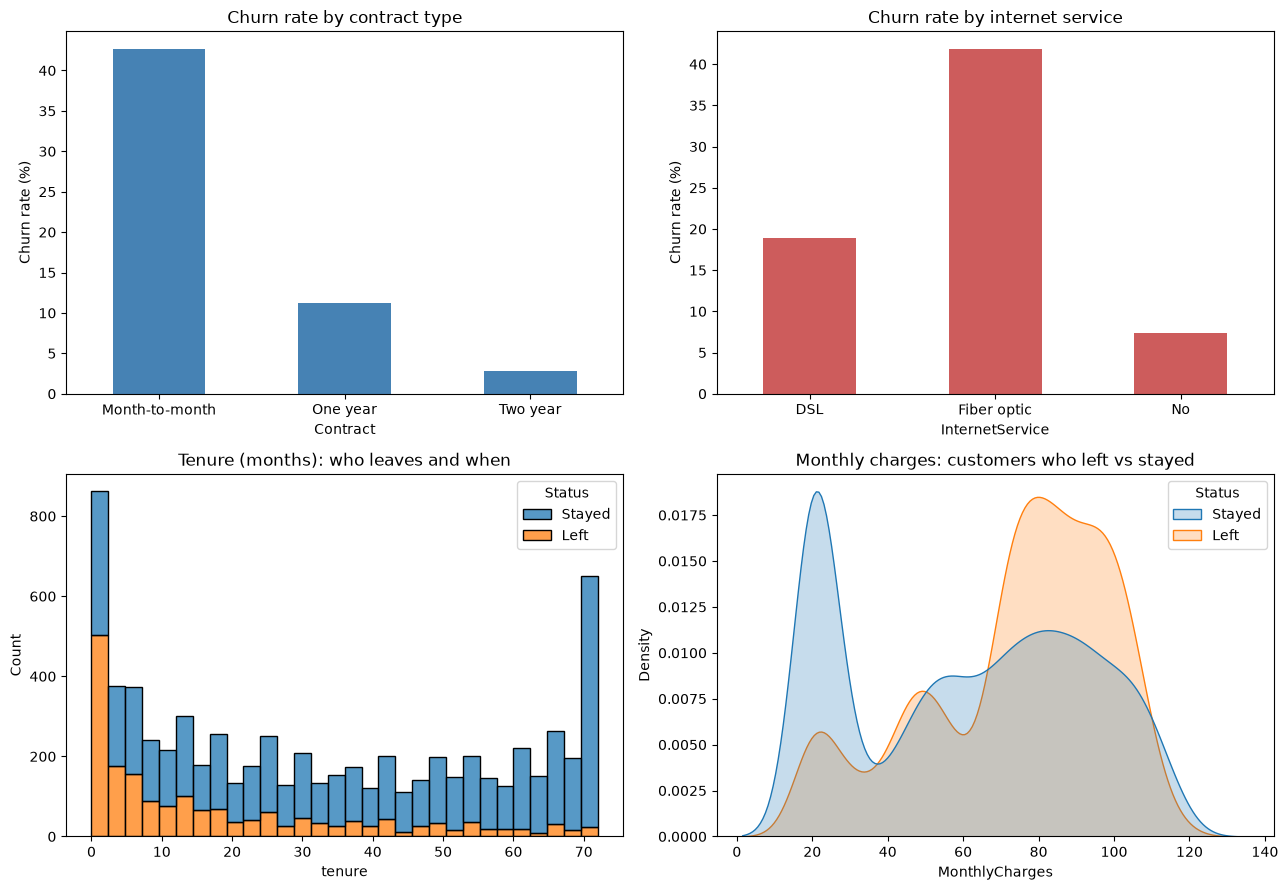

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("images", exist_ok=True)   # folder to save charts for the README

# a copy with readable labels, just for plotting
plot_df = df.assign(Status=df["Churn"].map({1: "Left", 0: "Stayed"}))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Churn rate by contract type
(df.groupby("Contract")["Churn"].mean() * 100).plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Churn rate by contract type")
axes[0, 0].set_ylabel("Churn rate (%)")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Churn rate by internet service
(df.groupby("InternetService")["Churn"].mean() * 100).plot(kind="bar", ax=axes[0, 1], color="indianred")
axes[0, 1].set_title("Churn rate by internet service")
axes[0, 1].set_ylabel("Churn rate (%)")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3. How long customers stay (tenure, in months)
sns.histplot(data=plot_df, x="tenure", hue="Status", bins=30, multiple="stack", ax=axes[1, 0])
axes[1, 0].set_title("Tenure (months): who leaves and when")

# 4. Monthly charges
sns.kdeplot(data=plot_df, x="MonthlyCharges", hue="Status", common_norm=False, fill=True, ax=axes[1, 1])
axes[1, 1].set_title("Monthly charges: customers who left vs stayed")

plt.tight_layout()
plt.savefig("images/eda-overview.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

# X = the clues (everything except Churn), y = the answer we want to predict
X = df.drop(columns="Churn")
y = df["Churn"]

# Turn text columns (like Contract) into 0/1 columns the model can use
X = pd.get_dummies(X, drop_first=True)

# Keep 20% of customers hidden for testing, 80% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Churn rate in train:", round(y_train.mean(), 3))
print("Churn rate in test:", round(y_test.mean(), 3))
print("Baseline accuracy (always guess 'stayed'):", round(1 - y_test.mean(), 3))

Training set: (5634, 30)
Test set: (1409, 30)
Churn rate in train: 0.265
Churn rate in test: 0.265
Baseline accuracy (always guess 'stayed'): 0.735


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                             eval_metric="logloss", random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)                    # learn from the training customers
    pred = model.predict(X_test)                   # predict the hidden customers
    prob = model.predict_proba(X_test)[:, 1]       # churn probability for each
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.807,0.658,0.567,0.609,0.842
XGBoost,0.800,0.656,0.516,0.578,0.846


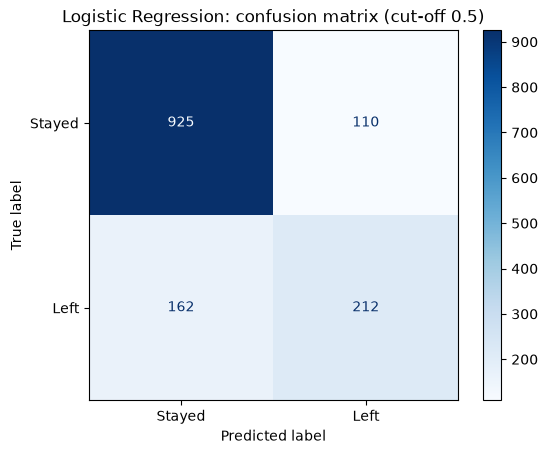

,Cut-off,Precision,Recall,Customers flagged
0,0.50,0.658,0.567,322
1,0.40,0.567,0.668,441
2,0.30,0.519,0.754,543
3,0.25,0.498,0.810,608


In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best = models["Logistic Regression"]
prob = best.predict_proba(X_test)[:, 1]

# 1. Confusion matrix at the default 0.5 cut-off
pred = (prob >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Stayed", "Left"], cmap="Blues"
)
plt.title("Logistic Regression: confusion matrix (cut-off 0.5)")
plt.savefig("images/confusion-matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. What happens if we lower the cut-off?
rows = []
for t in [0.5, 0.4, 0.3, 0.25]:
    p = (prob >= t).astype(int)
    rows.append({
        "Cut-off": t,
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "Customers flagged": int(p.sum()),
    })
pd.DataFrame(rows).round(3)

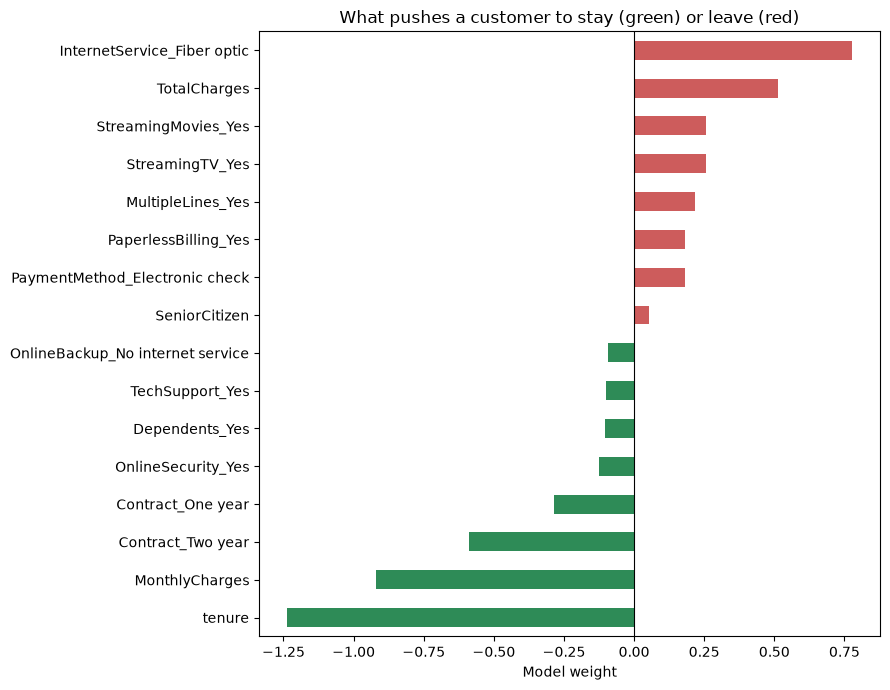

In [9]:
# Pull out the model's learned weights for each feature
lr = best.named_steps["logisticregression"]
coefs = pd.Series(lr.coef_[0], index=X_train.columns).sort_values()

# 8 strongest "stay" signals and 8 strongest "leave" signals
top = pd.concat([coefs.head(8), coefs.tail(8)])

colors = ["seagreen" if v < 0 else "indianred" for v in top]
top.plot(kind="barh", figsize=(9, 7), color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("What pushes a customer to stay (green) or leave (red)")
plt.xlabel("Model weight")
plt.tight_layout()
plt.savefig("images/feature-importance.png", dpi=150, bbox_inches="tight")
plt.show()